# INSURANCE CLAIM FORECASTING

Import packages and plotting setup:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import json

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from statsmodels.genmod.generalized_linear_model import GLMResultsWrapper


from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import mean_poisson_deviance
from skopt import BayesSearchCV
from skopt.space import Real, Integer

from xgboost import XGBRegressor
import xgboost as xgb

# Plotting setup
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Data exploration and preparation

Data loading and division into continuous and categorical variables, with special attention to join key, target and offset variable:

In [2]:
def load_data(file_path:str)->pd.DataFrame:
    """
    This function loads dataset. The structure of it is assumed to be a CSV file containing 12 columns (+ IDpol):
    - IDpol: Policy ID (join key)
    - ClaimNb: Number of claims during the exposure period
    - Exposure: Length of exposure (in years)
    - Area: Geographic area code
    - VehPower: Ordered category of vehicle power
    - VehAge: Vehicle age (years)
    - DrivAge: Driver age (years)
    - BonusMalus: 50–350 scale (<100 = bonus, >100 = malus)
    - VehBrand: Car brand (categorical)
    - VehGas: Fuel type (Diesel or Regular)
    - Density: Population density (inhabitants/km²) of driver's location
    - Region: Policy region code
    :param filepath: the path to the CSV file
    :return: loaded pandas dataframe
    """
    df = pd.read_csv(file_path)
    print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns.")

    # Vehicle power will be treated as categorical variable, so string
    # type will be more appropriate
    df['VehPower'] = df['VehPower'].astype(str)
    print("The column VehPower is converted from numerical to string type.")

    return df

file_path = 'data/freMTPL2freq.csv'

df_columns = {
    "continuous_cols": ['VehAge','DrivAge','BonusMalus','Density'],
    "categorical_cols": ['Area','VehPower','VehBrand','VehGas','Region'],
    "join_key_col": 'IDpol',
    "target_col": 'ClaimNb',
    "exposure_col": 'Exposure' # offset variable in GLM
}
print(f"Continuous variables ({len(df_columns["continuous_cols"])}): {df_columns["continuous_cols"]}")
print(f"Categorical variables ({len(df_columns["categorical_cols"])}): {df_columns["categorical_cols"]}")

#df = load_data(file_path)

Continuous variables (4): ['VehAge', 'DrivAge', 'BonusMalus', 'Density']
Categorical variables (5): ['Area', 'VehPower', 'VehBrand', 'VehGas', 'Region']


Initial plots, needed to take a first look at the variables, and notice some visible irregularities:

In [3]:
def variable_plots(df:pd.DataFrame, df_columns:dict, option:str='all')->None:
    """
    Plot of raw values of each variable in dataframe (except join_key_col)
    :param df:
    :param df_columns: dictionary with the names of the columns
    :param option: choose what do you want to plot: 'all', 'target', 'exposure', 'cont', 'cat'
    :return:
    """
    # Plotting the target variable distribution
    opt = option
    if option not in ['all', 'target', 'exposure', 'cont', 'cat']:
        opt = 'target'

    # Plotting the target variable distribution
    if opt in ['all','target']:
        plt.figure()
        ax = sns.countplot(data=df, x=df_columns["target_col"], color='crimson')
        for container in ax.containers:
            ax.bar_label(container, fmt='%d', padding=3)
        plt.title(f'Distribution of {df_columns["target_col"]}')
        plt.show()

    # Plotting the exposure variable distribution
    if opt in ['all','exposure']:
        plt.figure()
        sns.histplot(df[df_columns["exposure_col"]], kde=True, color='crimson')
        plt.title(f'Distribution of {df_columns["exposure_col"]}')
        plt.show()

    # Plotting the continuous variable distributions
    if opt in ['all','cont']:
        print("Plotting continuous variable distributions...")
        for col in df_columns["continuous_cols"]:
            plt.figure()
            sns.histplot(df[col], kde=True, color='teal')
            plt.title(f"Distribution of continuous feature: {col}")
            plt.show()

    # Plotting the categorical variable distributions
    if opt in ['all','cat']:
        print("Plotting categorical variable distributions...")
        for col in df_columns["categorical_cols"]:
            plt.figure()
            top_cats = df[col].value_counts().head(15).index
            sns.countplot(data=df[df[col].isin(top_cats)], x=col, order=top_cats, color='coral')
            plt.title(f"Distribution of categorical feature: {col} (Top 15 or all)")
            plt.show()

#variable_plots(df,df_columns,'all')

Missing values analysis and outlier treatment: We will report the number of missing variables. As it seems that there aren't any of them, we will go right to the outlier handling.

There are several ways to do this. Some of them are automatic, some are manual. One can examine the limits of reasonable values based on fundamental constraints (e.g. number of (something) >0) or based on someone's expertise and experience. Some automatic methods are based on setting limits at specific quantiles (percentiles, commonly 1st and 99th).

The outliers for continuous variables will be removed. For categorical ones, one needs to look for inconsistencies between the database and the documentation. Those inconsistencies are often caused by non-synchronous updates of different databases that are often being joined, and documentation.

In [4]:
def initial_treatment(df:pd.DataFrame) ->pd.DataFrame:
    """
    This function does some initial treatment. It gives the missing value report and removes outliers
    :param df: dataframe
    :return: treated dataframe
    """
    missing_report = pd.DataFrame({
        'Missing values': df.isnull().sum(),
        'Percentage (%)': (df.isnull().sum() / len(df)) * 100 if len(df)>0 else 0
    })
    print("--- Missing data summary ---")
    print(missing_report)

    print("__________________________________")

    print(f"\nThe initial number of rows: {len(df)}")
    df_treated = df.copy()

    # OPTION 1: manual examining of reasonable values
    print("\nOutlier treatment (examination of reasonable values)...")

    # Exposure: >2 - shouldn't exist in a table
    df_treated = df_treated[(df_treated['Exposure'] > 0) & (df_treated['Exposure'] <= 2.0)]

    # VehAge: >40 some could be extreme cases, but the age of ~100 is unacceptable
    df_treated = df_treated[df_treated['VehAge'] <= 40]

    # DrivAge: >= 95 is too much, further investigation needed
    df_treated = df_treated[(df_treated['DrivAge'] >= 18) & (df_treated['DrivAge'] <= 95)]

    # BonusMalus: 50 <= BonusMalus <= 350
    df_treated = df_treated[(df_treated['BonusMalus'] >= 50) & (df_treated['BonusMalus'] <= 350)]

    #______________________________________________________________________________

    # OPTION 2: using Winsorization (capping at 1st and 99th percentiles)
    """print("\n--- Outlier treatment (capping at 1st & 99th percentiles) ---")
    df_treated = df.copy()

        for col in continuous_cols:
        lower_limit = df[col].quantile(0.01)
        upper_limit = df[col].quantile(0.99)

        # Track how many values are affected
        outliers_lower = (df[col] < lower_limit).sum()
        outliers_upper = (df[col] > upper_limit).sum()

        # Apply capping
        df_treated[col] = np.clip(df_treated[col], lower_limit, upper_limit)
        print(f"{col}: Capped {outliers_lower} lower values and {outliers_upper} upper values.")"""

    print(f"\nThe final number of rows: {len(df_treated)}")
    return df_treated

#df_treated = initial_treatment(df)

#print("Plotting the continuous variables again to check for any differences...")
#variable_plots(df_treated,df_columns,'cont')

Plotting the target variable versus each predictor: From this we can also gain a feeling for what could be important. Aggregation will be needed, i.e. looking at the one number that describes the nature of target for a category (in our case: total number of claims divided by total exposure). For continuous variables, we will use binning. This practice needs to be conducted with care, because we now ignore the variation within each interval.

In [5]:
def plot_predictor_vs_frequency(df:pd.DataFrame, predictor:str, is_continuous:bool=False, bins:list[float]=None) ->None:
    """
    Plots the true actuarial Claim Frequency against an individual predictor.
    :param df: pandas dataframe
    :param predictor: predictor variable
    :param is_continuous: if the variable is continuous the binning is required
    :param bins: if is_continuous=True we provide bin edges
    :return:
    """
    plot_df = df.copy()

    # Binning of continuous variables
    if is_continuous:
        if bins is None:
            plot_df[f'{predictor}_binned'] = pd.qcut(plot_df[predictor], q=5, duplicates='drop').astype(str)
        else:
            plot_df[f'{predictor}_binned'] = pd.cut(plot_df[predictor], bins=bins).astype(str)
        group_col = f'{predictor}_binned'
    else:
        group_col = predictor

    # Aggregation
    aggregated = plot_df.groupby(group_col).agg(
        total_claims=('ClaimNb', 'sum'),
        total_exposure=('Exposure', 'sum')
    ).reset_index()
    aggregated['Claim_Frequency'] = aggregated['total_claims'] / aggregated['total_exposure']


    plt.figure()
    sns.barplot(x=group_col, y='Claim_Frequency', hue=group_col, data=aggregated, palette='Blues_r', legend=False)
    plt.title(f'Claim frequency vs {predictor}')
    plt.ylabel('Claim frequency (claims / exposure)')
    plt.xlabel(predictor)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

"""cont_bins_vals = [[0,5,10,15,20,30,40], # VehAge
                  [18,20,25,30,40,60,80,100], # DrivAge
                  [50,80,100,150,200,350], # BonusMalus
                  [x * 1000 for x in [0,1,3,5,10,15,20,25,30]] # Density
                  ]

cont_bins = dict(zip(df_columns["continuous_cols"],cont_bins_vals))

for col in df_columns['continuous_cols']:
    plot_predictor_vs_frequency(df_treated,col,True,cont_bins[col])
for col in df_columns['categorical_cols']:
    plot_predictor_vs_frequency(df_treated,col)"""

'cont_bins_vals = [[0,5,10,15,20,30,40], # VehAge\n                  [18,20,25,30,40,60,80,100], # DrivAge\n                  [50,80,100,150,200,350], # BonusMalus\n                  [x * 1000 for x in [0,1,3,5,10,15,20,25,30]] # Density\n                  ]\n\ncont_bins = dict(zip(df_columns["continuous_cols"],cont_bins_vals))\n\nfor col in df_columns[\'continuous_cols\']:\n    plot_predictor_vs_frequency(df_treated,col,True,cont_bins[col])\nfor col in df_columns[\'categorical_cols\']:\n    plot_predictor_vs_frequency(df_treated,col)'

In [6]:
def logging_cont_vars(df:pd.DataFrame, df_columns:dict) ->tuple[pd.DataFrame,dict]:
    """
    Transforming continuous variables into their log versions: log(x), log(x+1),
    dependent on the natural range of values of each variable.
    :param df: dataframe
    :param df_columns: dict with columns
    :return: transformed dataferame and the appropriate dict
    """
    trans_names = []
    df_transformed = df.copy()

    for col in df_columns["continuous_cols"]:
        trans_names.append(f'ln_{col}')
        if (df[col] <= 0).any():
            df_transformed[col] = np.log1p(df[col])
        else:
            df_transformed[col] = np.log(df[col])

    df_transformed.rename(columns=dict(zip(df_columns["continuous_cols"],trans_names)), inplace=True)

    df_trans_columns = df_columns.copy()
    df_trans_columns["continuous_cols"] = trans_names

    return df_transformed, df_trans_columns

#df_transformed, df_transformed_columns = logging_cont_vars(df_treated,df_columns)

Adding a variable is not always informative. Variables can be correlated in different ways, which can mean that by introducing a new variable introduces more noise than information. Some of these problems are:
- 2-way correlation
- multicollinearity
- aliasing

We will take a look at the 2-way correlation matrix and VIF coefficients to track these problems:

In [7]:
def corr_matrix_plot(df:pd.DataFrame, df_columns:dict) ->None:
    """
    Plots the correlation matrix for continuous features of dataframe
    :param df: dataframe
    :param df_columns: dict with columns
    :return:
    """
    plt.figure()
    corr_matrix = df_transformed[df_columns["continuous_cols"]].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
    plt.title("Correlation matrix")
    plt.show()

#corr_matrix_plot(df_transformed, df_transformed_columns)

Looking at the correlation matrix, we could consider and further investigate the relation between ln_BonusMalus and ln_DriverAge. Even the ln_BonusMalus-ln_Density pair could be called suspicious. In this case, we are not going to discard any of these variables. The rest of the correlation coefficients are fairly close to zero, which indicates that there is no linear relationship between these pairs of variables, fundamentally.

To check for multicollinearity, we can run VIF analysis. The VIF for any predictor is a measure of how much the (squared) standard error for the predictor is increased due to the presence of collinearity with other predictors. It is determined for each predictor by running a linear model setting the predictor as the target and using all the other predictors as inputs, and measuring the predictive power of that model. A common statistical rule of thumb is that a VIF greater than 10 is considered high. However, where large VIFs are indicated, it is important to look deeper into the collinearity structure in order to make an informed decision about how best to handle it in the model.

In [8]:
def VIF_analysis(df:pd.DataFrame, df_columns:dict) ->None:
    """
    VIF analysis of the data.
    VIF>10 indicates serious multicollinearity issues with given variable - it is not informative in linear models if the rest of the variables remain
    VIF>5 is still dangerous
    :param df: dataframe
    :param df_columns: dict with columns
    :return:
    """
    # Extracting the relevant variables
    vif_data = df[df_columns["continuous_cols"] + df_columns["categorical_cols"]]

    # Preparing the data for VIF analysis
    vif_data_encoded = pd.get_dummies(vif_data, columns=df_columns["categorical_cols"], drop_first=True)
    vif_data_encoded = vif_data_encoded.dropna()
    vif_data_encoded = vif_data_encoded.astype(float)
    vif_data_with_const = add_constant(vif_data_encoded)

    vif_df = pd.DataFrame()
    vif_df["Feature"] = vif_data_with_const.columns
    vif_df["VIF"] = [
        variance_inflation_factor(vif_data_with_const.values, i)
        for i in range(vif_data_with_const.shape[1])
    ]
    print("--- Variance Inflation Factors (VIF) ---")
    print(vif_df[vif_df["Feature"] != "const"].to_string(index=False))

The results indicate that the most of the variables do not have a problem with multicollinearity. However, there are some variables that have VIF coefficients greater than 5 (even 10). Those are ln_density and the area variable. These two are highly correlated by nature. We should drop one of these. We will go with Area, but the other option should be considered as well.

We are going to divide data into the train and test categories. We do this to validate the model once it is trained. If the results are good, we train model with all the data. We do not test this model, as we don't have data it is not trained on, but because of previous success, we believe that it will be slightly more accurate than the one trained using training data only. The alternative is division into the train/validation/test parts, where we are training and validating the model with the former two, and only test (never train) with the test part.

Later, we will validate the model by running k-fold cross-validation. In many insurance modeling applications, where the data is carefully selected and transformed using the insights we god by looking at it, this approach is not as good as in the most of the other applications.

Here is the unified procedure from loading to train-test split of data:

Dataset loaded: 678013 rows, 12 columns.
The column VehPower is converted from numerical to string type.


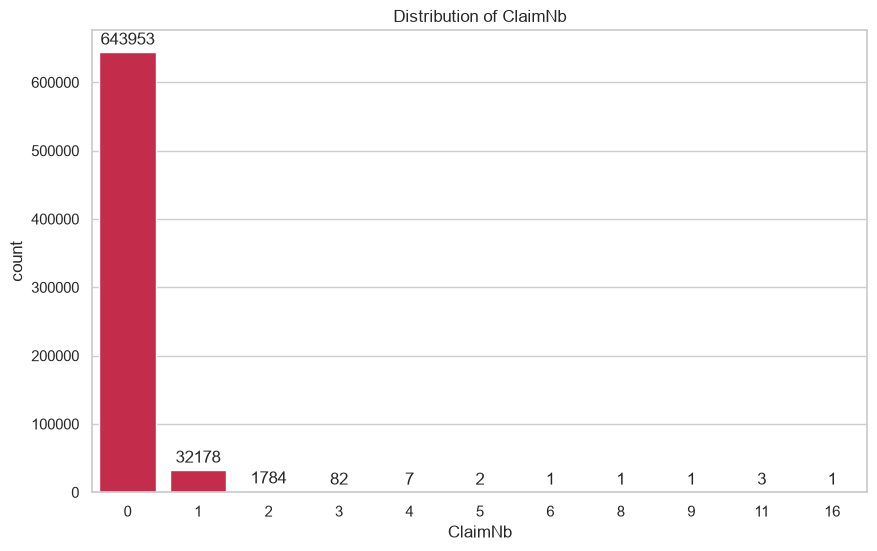

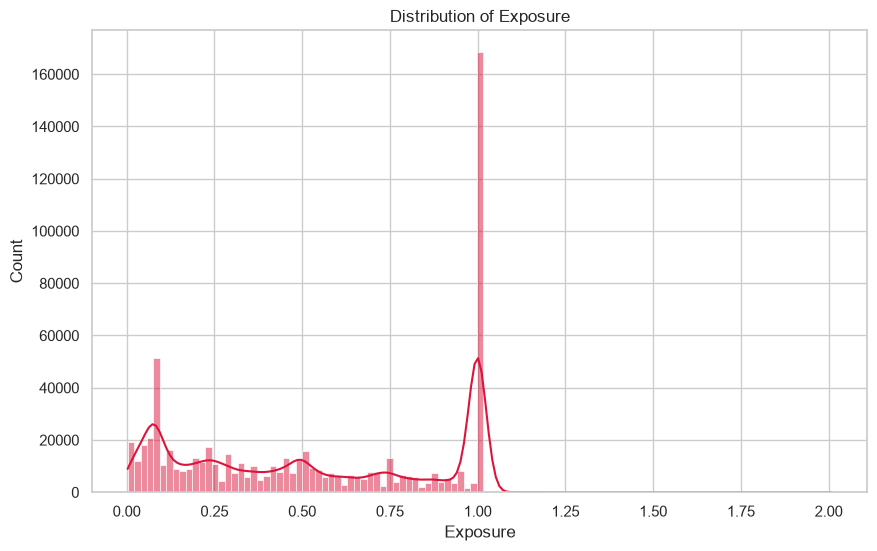

Plotting continuous variable distributions...


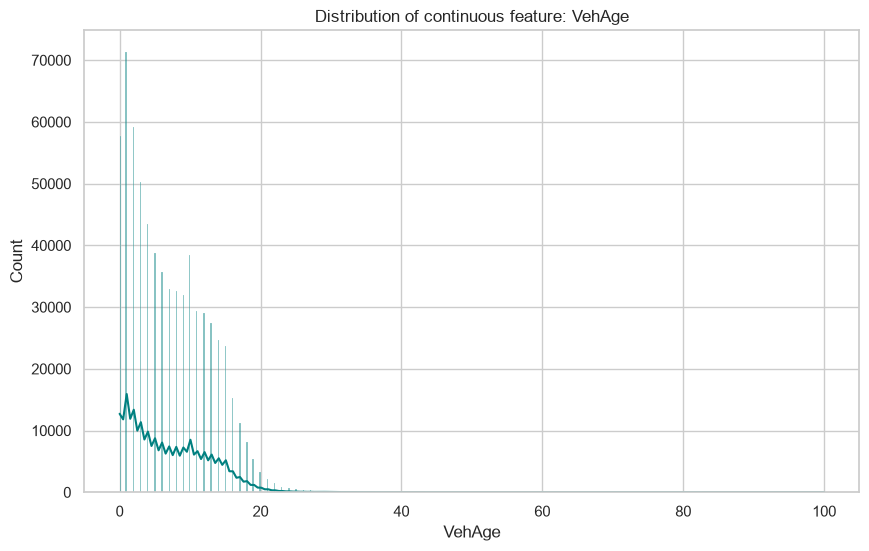

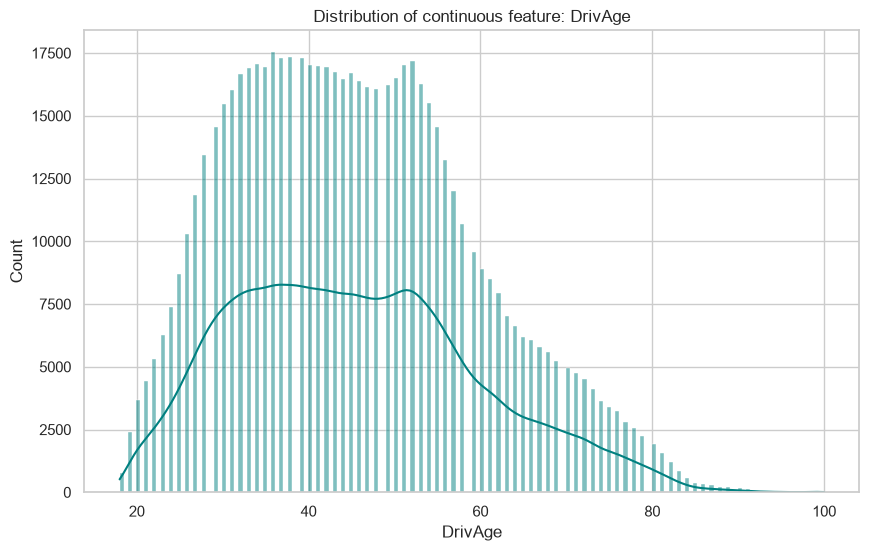

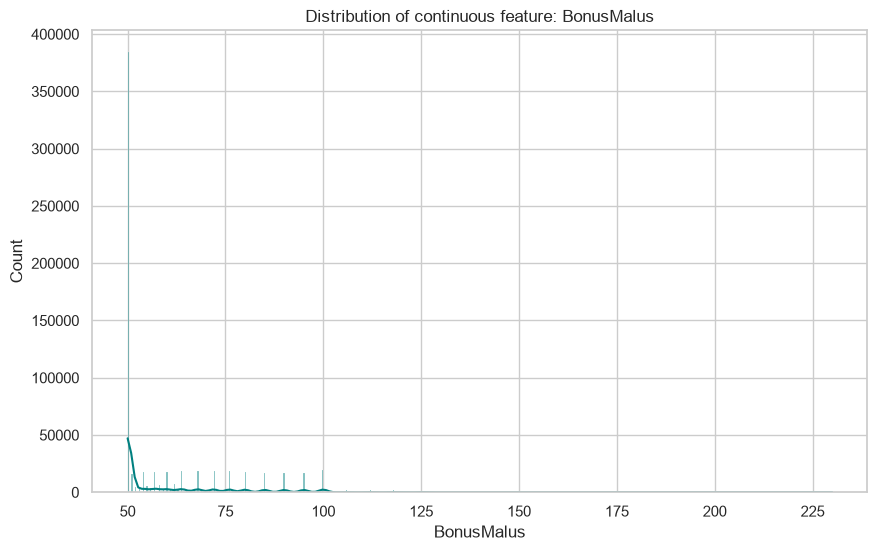

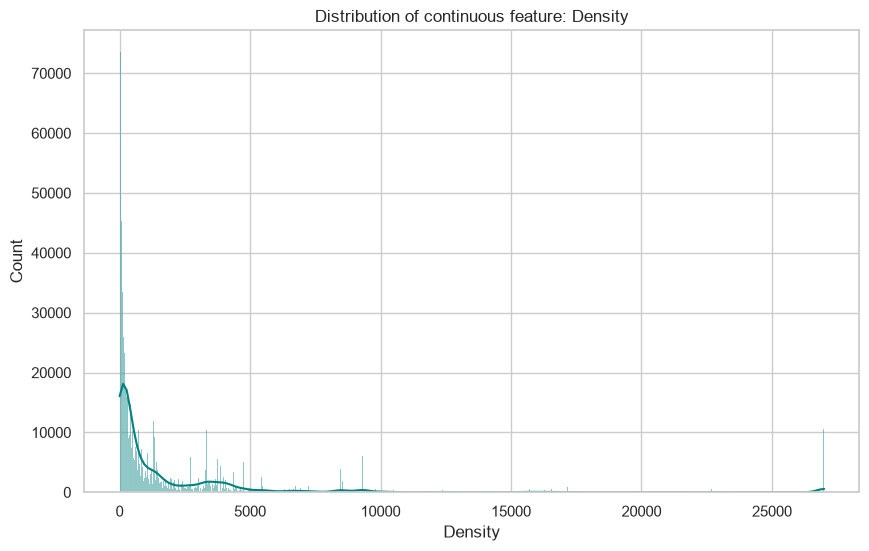

Plotting categorical variable distributions...


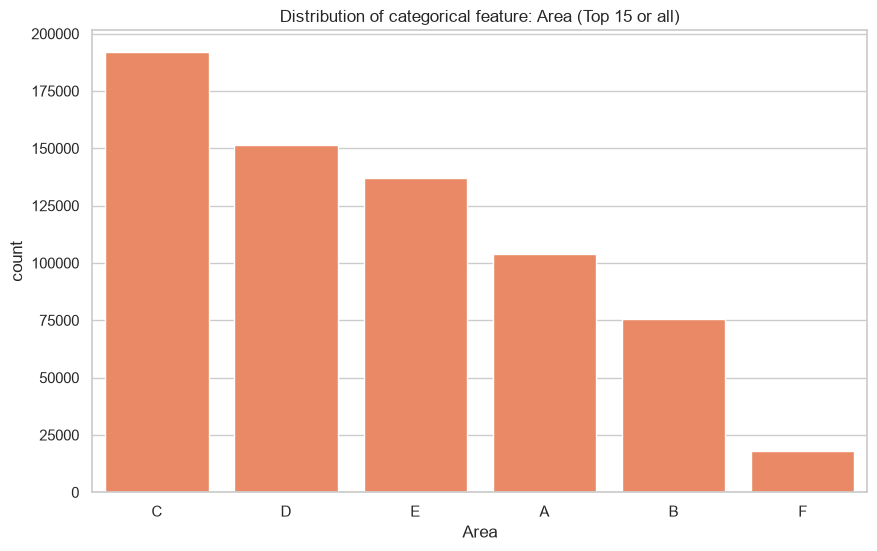

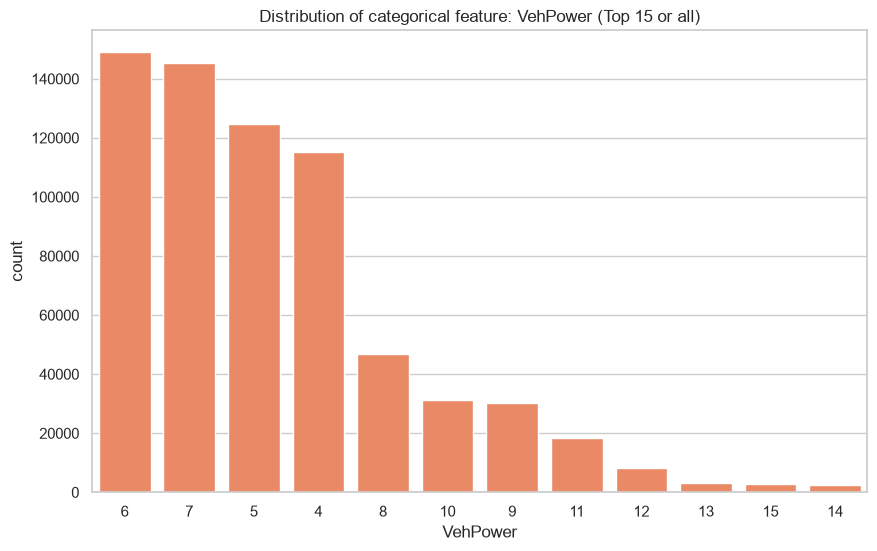

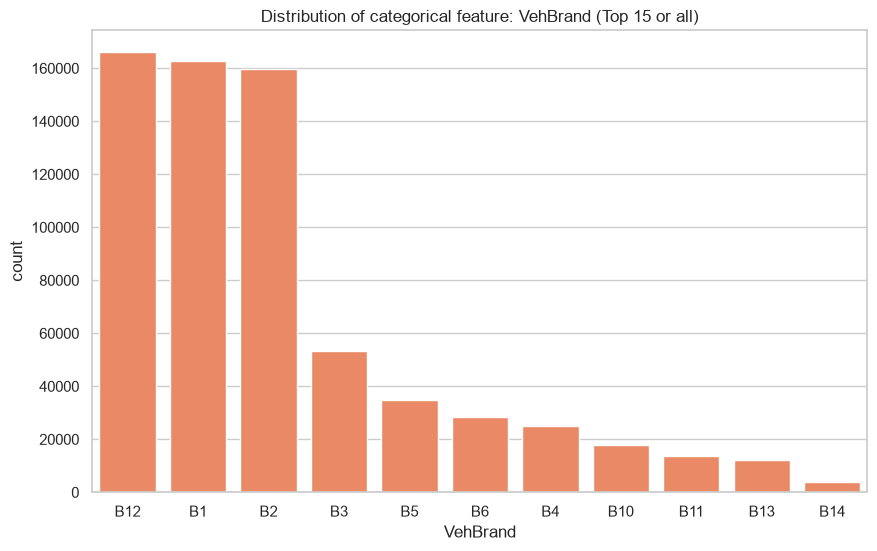

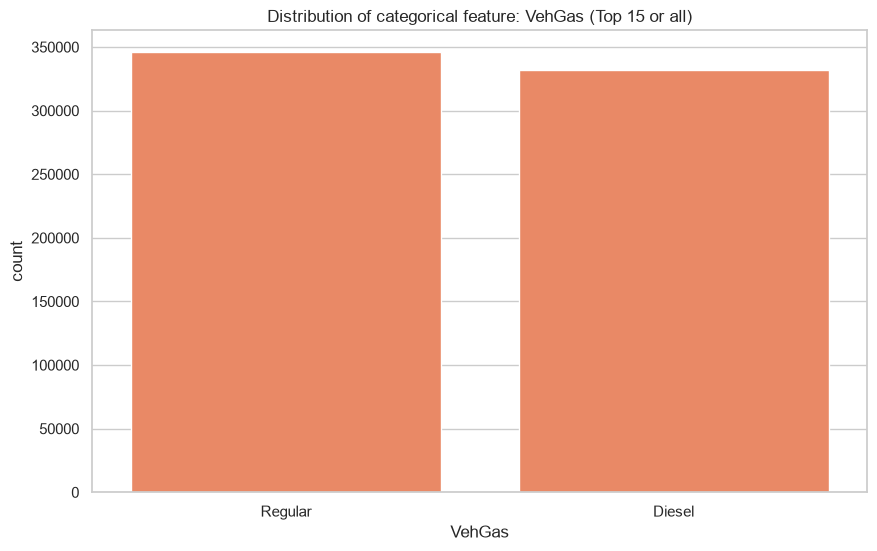

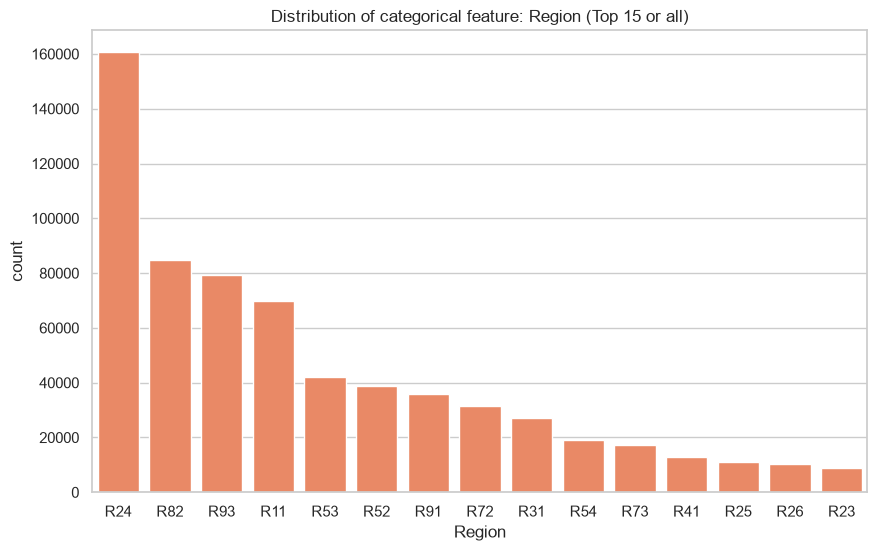

--- Missing data summary ---
            Missing values  Percentage (%)
IDpol                    0             0.0
ClaimNb                  0             0.0
Exposure                 0             0.0
Area                     0             0.0
VehPower                 0             0.0
VehAge                   0             0.0
DrivAge                  0             0.0
BonusMalus               0             0.0
VehBrand                 0             0.0
VehGas                   0             0.0
Density                  0             0.0
Region                   0             0.0
__________________________________

The initial number of rows: 678013

Outlier treatment (examination of reasonable values)...

The final number of rows: 677678
Plotting continuous variable distributions...


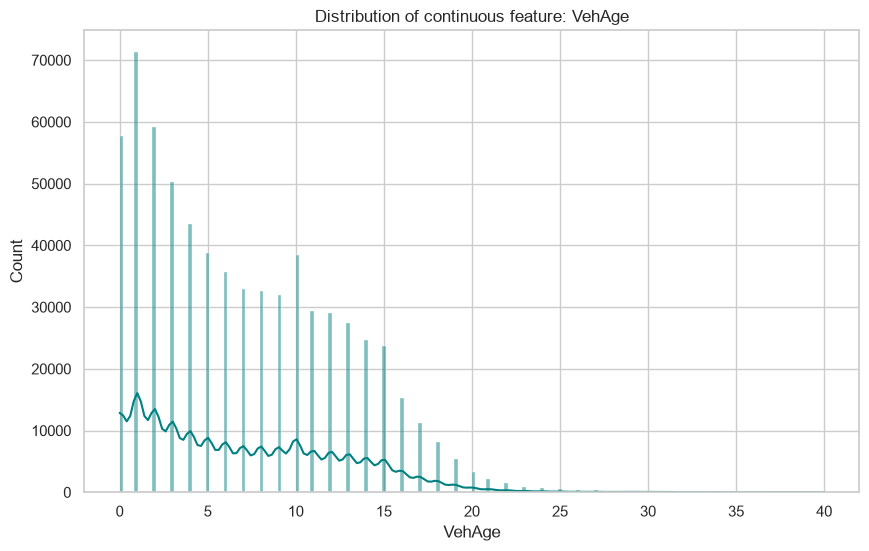

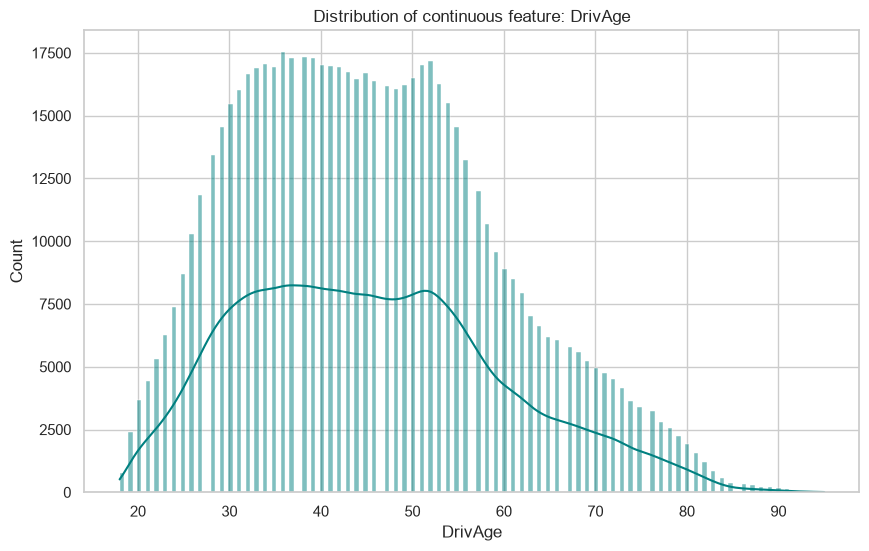

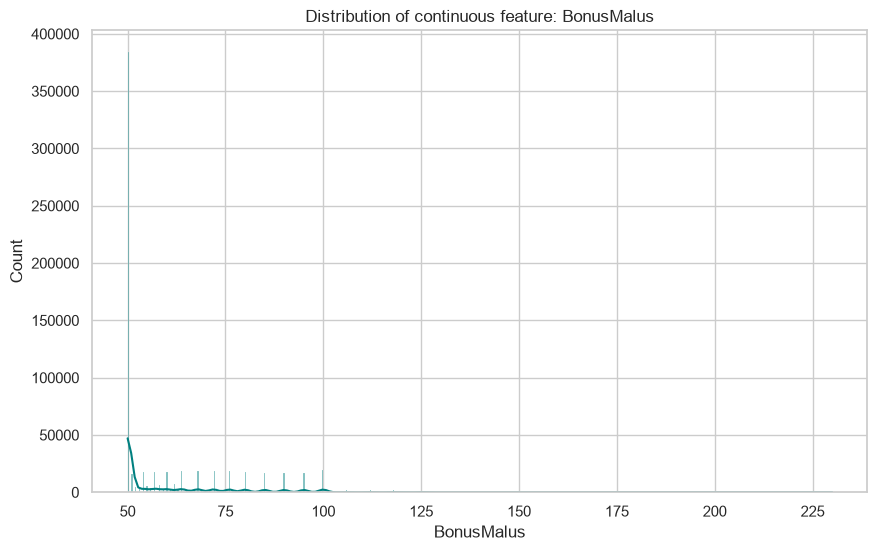

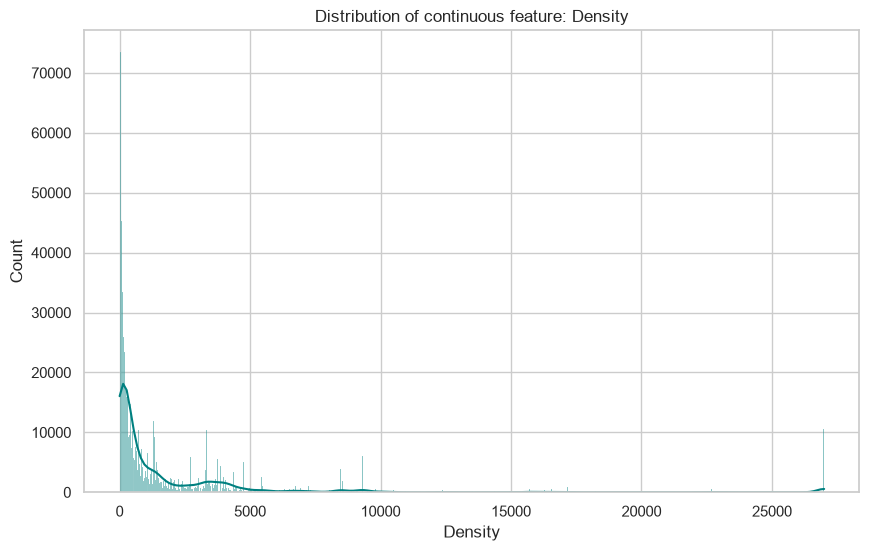

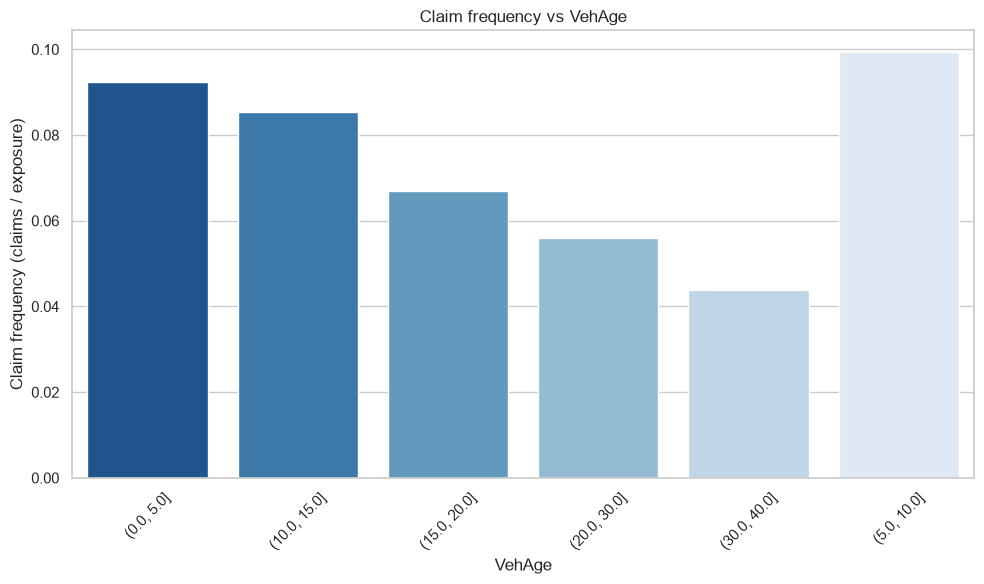

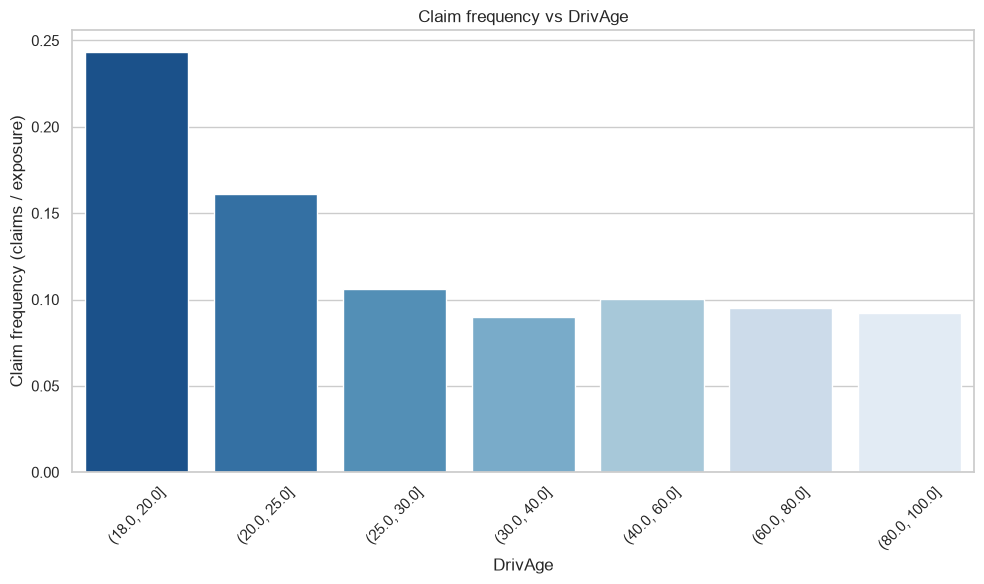

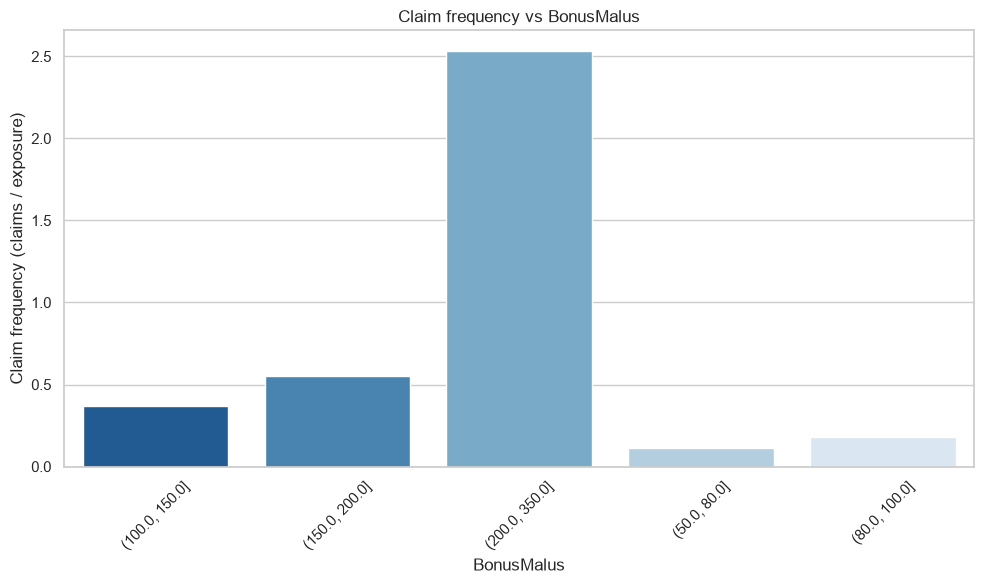

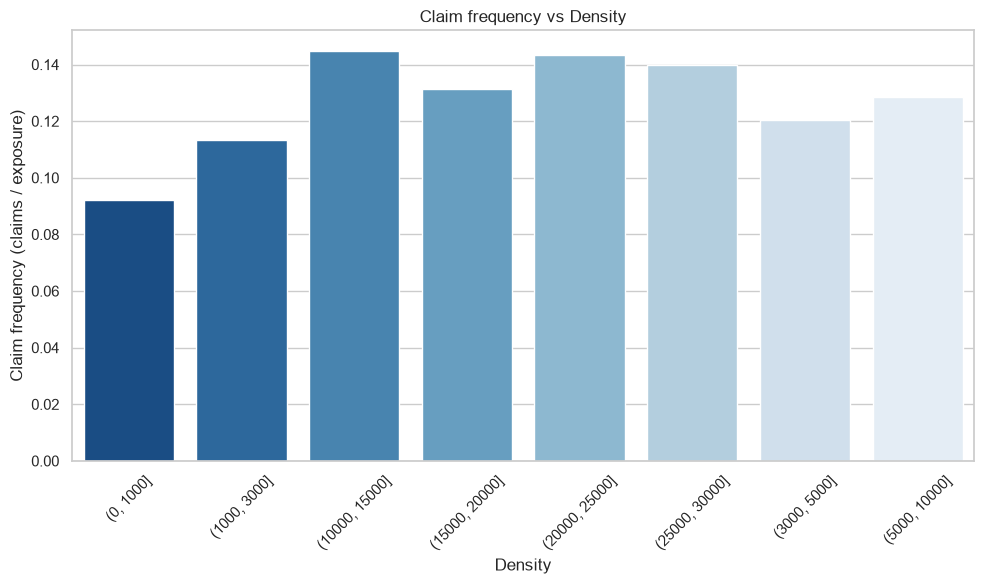

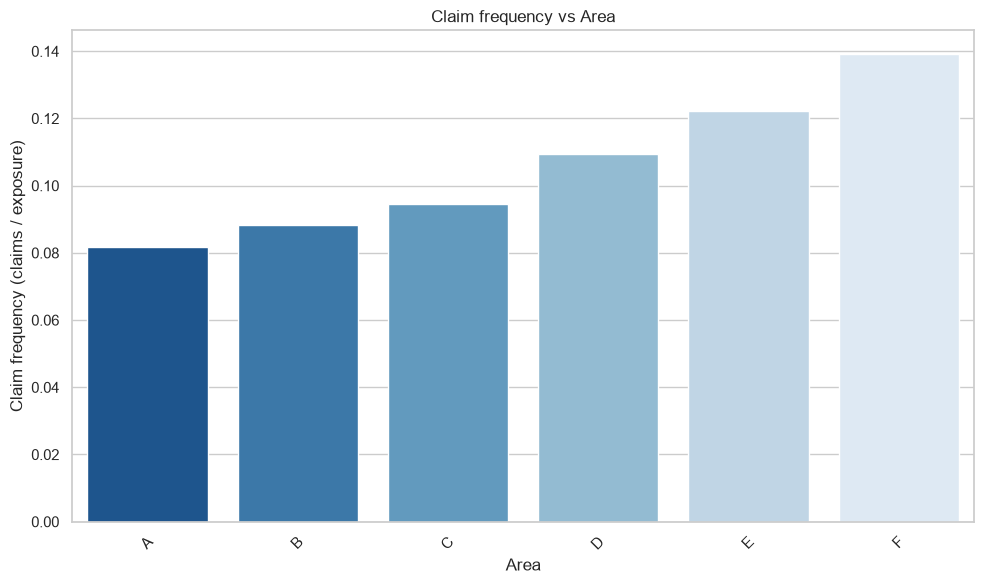

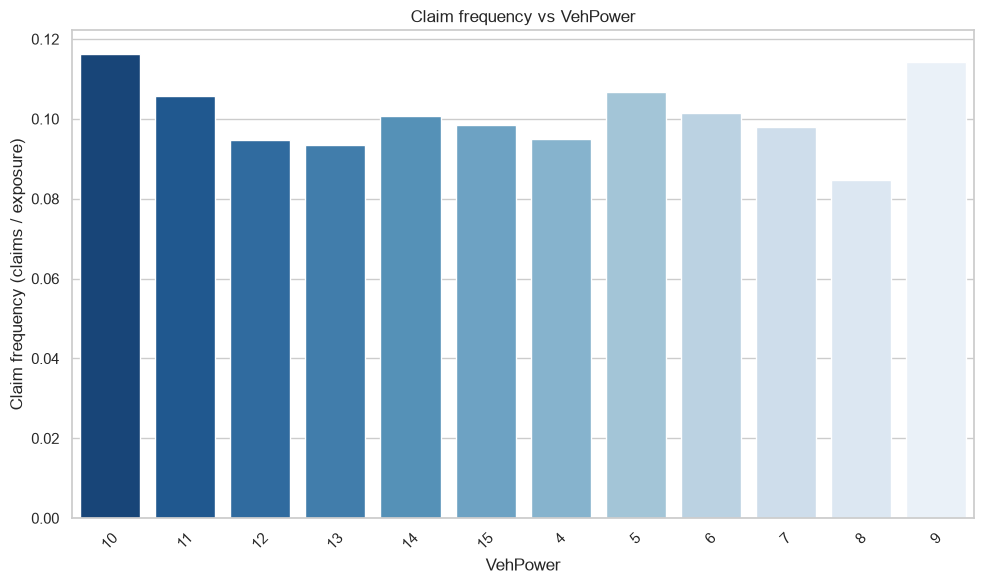

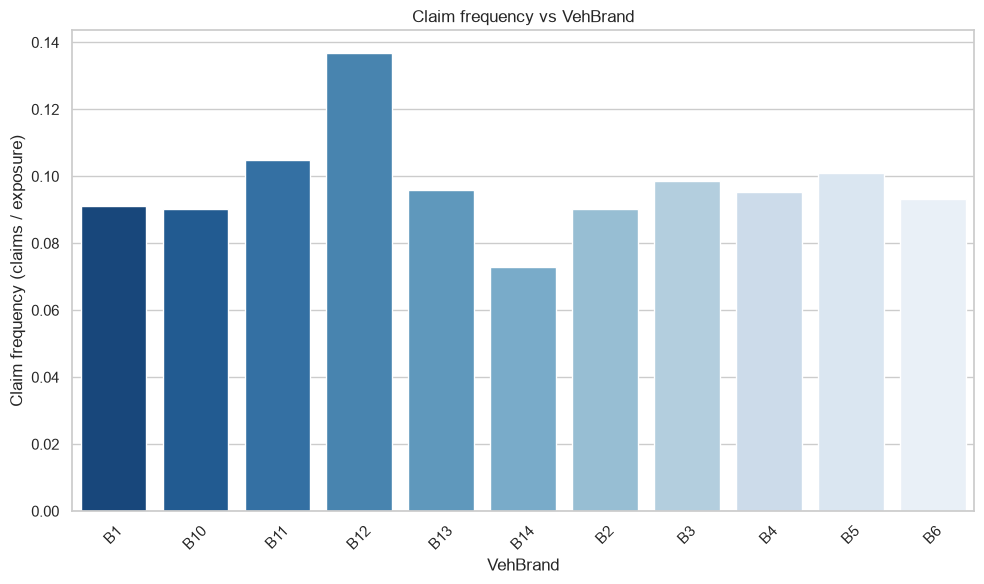

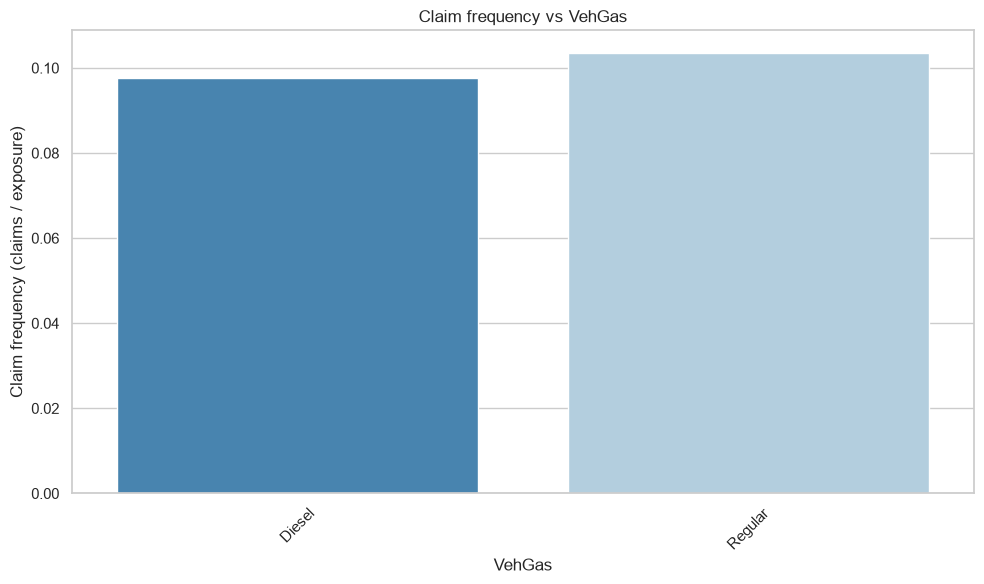

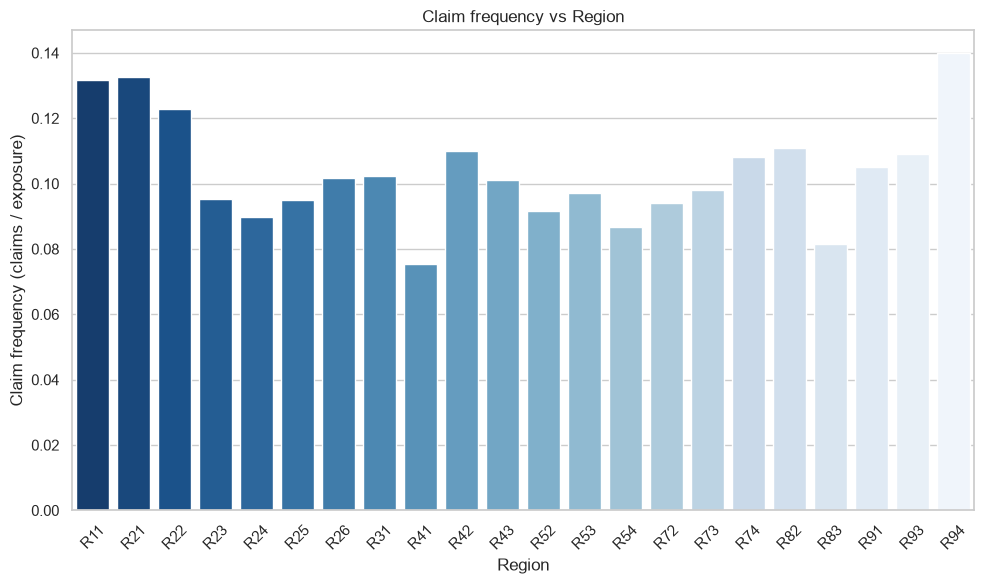

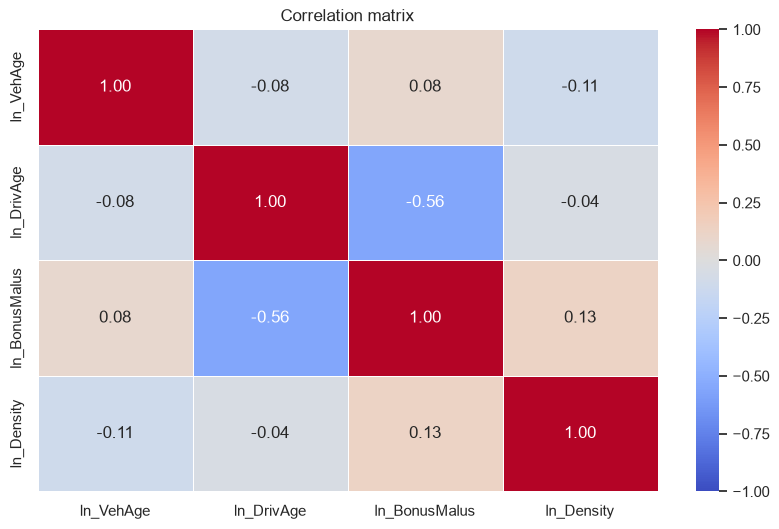

--- Variance Inflation Factors (VIF) ---
       Feature       VIF
     ln_VehAge  1.437486
    ln_DrivAge  1.497914
 ln_BonusMalus  1.503671
    ln_Density 19.932130
        Area_B  2.206301
        Area_C  7.782544
        Area_D 15.521219
        Area_E 25.639823
        Area_F  7.916871
   VehPower_11  1.554412
   VehPower_12  1.263533
   VehPower_13  1.141861
   VehPower_14  1.083282
   VehPower_15  1.094208
    VehPower_4  4.047640
    VehPower_5  4.284140
    VehPower_6  4.772612
    VehPower_7  4.573572
    VehPower_8  2.359035
    VehPower_9  1.905032
  VehBrand_B10  1.170261
  VehBrand_B11  1.143557
  VehBrand_B12  2.213705
  VehBrand_B13  1.074429
  VehBrand_B14  1.027234
   VehBrand_B2  1.534520
   VehBrand_B3  1.252927
   VehBrand_B4  1.128041
   VehBrand_B5  1.176631
   VehBrand_B6  1.140424
VehGas_Regular  1.183748
    Region_R21  1.064623
    Region_R22  1.160648
    Region_R23  1.172199
    Region_R24  4.025076
    Region_R25  1.233211
    Region_R26  1.231635
    Regio

In [9]:
df = load_data(file_path)
variable_plots(df,df_columns,'all')
df_treated = initial_treatment(df)
variable_plots(df_treated,df_columns,'cont')

cont_bins_vals = [[0,5,10,15,20,30,40], # VehAge
                  [18,20,25,30,40,60,80,100], # DrivAge
                  [50,80,100,150,200,350], # BonusMalus
                  [x * 1000 for x in [0,1,3,5,10,15,20,25,30]] # Density
                  ]

cont_bins = dict(zip(df_columns["continuous_cols"],cont_bins_vals))

for col in df_columns['continuous_cols']:
    plot_predictor_vs_frequency(df_treated,col,True,cont_bins[col])
for col in df_columns['categorical_cols']:
    plot_predictor_vs_frequency(df_treated,col)

df_transformed, df_transformed_columns = logging_cont_vars(df_treated,df_columns)

corr_matrix_plot(df_transformed, df_transformed_columns)

VIF_analysis(df_transformed,df_transformed_columns) # takes longer to finish (compared to the other commands, and is not neccessary for the rest of the code to run)

train_df, test_df = train_test_split(df_transformed, test_size=0.2, random_state=42)

## GLM

Let's take a look at the idea of GLM:
$$g(\mu) = \beta_0 + \sum_{i=1}^{p}\beta_i \cdot x_i + offset $$
If we are doing Poisson regression, we will use link function $g(\mu)=ln(\mu)$ (or $ln(\mu+1)$, because the variable we are predicting is the number of claims that have value zero most of the time). Commonly, we don't want the relation between target and predictor variable to be exponential in nature. Therefore, one common transformation of variable is logaritmic one: $ln(x)$ or $ln(f(x))$, where $f(x)$ is some transformation needed for argument of ln function to be strictly positive. After exponentiation of the equation above, in case of having $ln(x_i)$ and $ln(offset)$, we have:
$$\mu = e^{\beta_0} \cdot \prod_{i=1}^{p} x_i^{\beta_i} \cdot offset$$

In [10]:
def create_GLM_formula(df_columns:dict, cat_baselines:dict, dropped_cols:list[str]) ->str:
    """
    Creates a formula for GLM model
    :param df_columns: dict with columns
    :param cat_baselines: baselines for categorical values
    :param dropped_cols: columns from df that won't be considered
    :return:
    """
    # creating terms for formula
    continuous_terms = [col for col in df_columns["continuous_cols"] if col not in dropped_cols]
    categorical_cols_final = [col for col in df_columns["categorical_cols"] if col not in dropped_cols]
    categorical_terms = []
    for col in categorical_cols_final:
        if col in dropped_cols:
            continue
        if col in cat_baselines:
            ref_level = cat_baselines[col]
            # statsmodels syntax to enforce a specific treatment baseline level
            term = f"C({col}, Treatment(reference='{ref_level}'))"
        else:
            # fallback if a feature is omitted from the dictionary above
            term = f"C({col})"
        categorical_terms.append(term)

    formula = f"{df_columns["target_col"]} ~ " + " + ".join(categorical_terms + continuous_terms)
    print("Generated GLM Model Formula:")
    print(formula, "\n")

    return formula

# columns that will not be considered in model building
dropped_cols = ['Area']

# Defining explicit baseline reference levels for categorical columns (the most common levels)
custom_baselines = {
    #'Area': 'C',         # Baseline geographic zone (dropped variable)
    'VehGas': 'Regular',  # Baseline fuel type
    'VehBrand': 'B12',    # Most common or stable car brand category
    'Region': 'R24',      # Baseline standard region
    'VehPower': '6'       # Baseline vehicle power
}

In [11]:
formula = create_GLM_formula(df_transformed_columns, custom_baselines, dropped_cols)
# Fitting the Poisson GLM with an exposure offset
# exposure=... automatically handles the log-exposure conversion internally
model = smf.glm(
    formula=formula,
    data=train_df,
    family=sm.families.Poisson(link=sm.families.links.Log()),
    exposure=train_df[df_transformed_columns["exposure_col"]]
).fit()

print(model.summary())

model_filename = "poisson_glm_model.pkl"
with open(model_filename, 'wb') as file:
    pickle.dump(model, file)
print(f"Model successfully saved to {model_filename}")

#with open(model_filename, 'rb') as file:
#    loaded_model = pickle.load(file)

Generated GLM Model Formula:
ClaimNb ~ C(VehPower, Treatment(reference='6')) + C(VehBrand, Treatment(reference='B12')) + C(VehGas, Treatment(reference='Regular')) + C(Region, Treatment(reference='R24')) + ln_VehAge + ln_DrivAge + ln_BonusMalus + ln_Density 

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542142
Model:                            GLM   Df Residuals:                   542094
Model Family:                 Poisson   Df Model:                           47
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1442e+05
Date:                Wed, 17 Jun 2026   Deviance:                   1.7324e+05
Time:                        21:35:40   Pearson chi2:                 1.37e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01252
Covariance Type:            no

From the model summary we can analyze the global metrics and the variables coefficients. Let's take a look at the coefficients. Continuous variables all have relevant coefficients, which is seen clearly from z statistics and p-values. Many levels of categorical variables are showing the potential of being zero. This means that the difference with the base level is not significant (at least, we didn't prove the significance of it). The sign of the coefficient tells us whether the increase in variable value increases or decreases the expected number of claims. The discussion on the exact values (exponentiated!) of these will be omitted here (as it requires a long analysis).

Next, we conduct the partial residual analysis. It shows the influence of changing one variable on target, assuming the rest of the variables stay fixed. This can help us look for non-linearities in model that we could further address. This is done for continuous variables, as with categorical ones, the information that we put in a model is the difference that each non-base level provides compared to its base level.


Generating Partial Residual plots for continuous features...


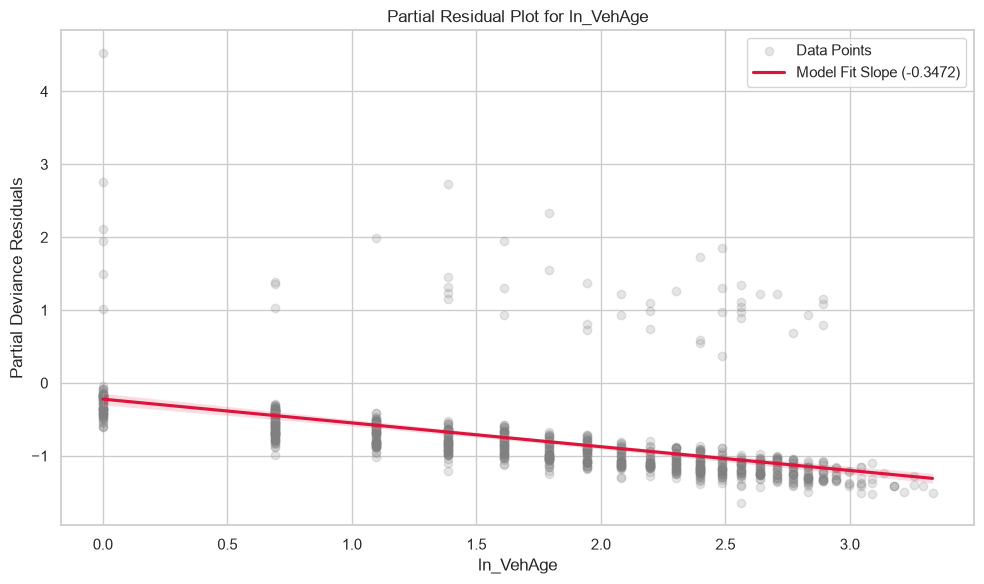

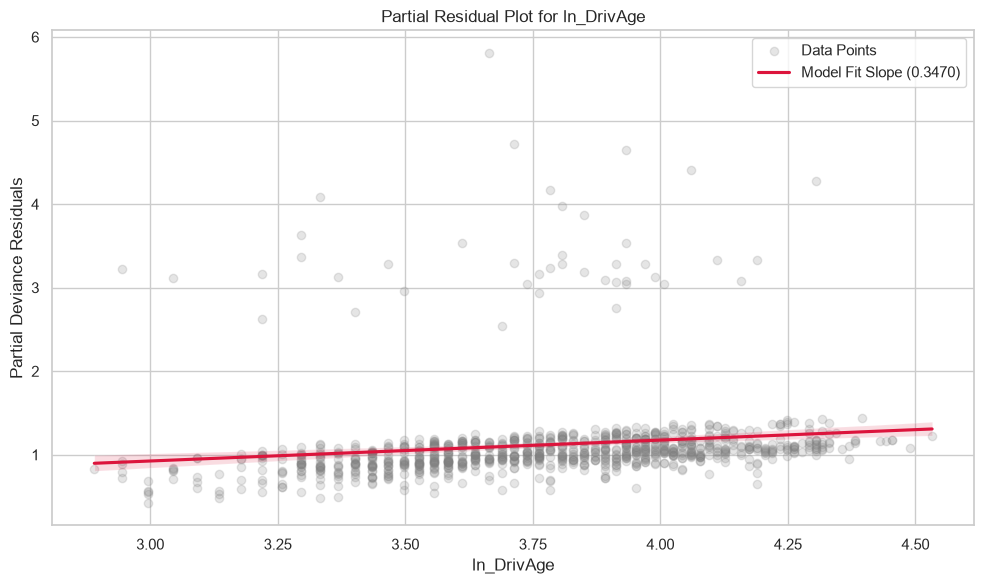

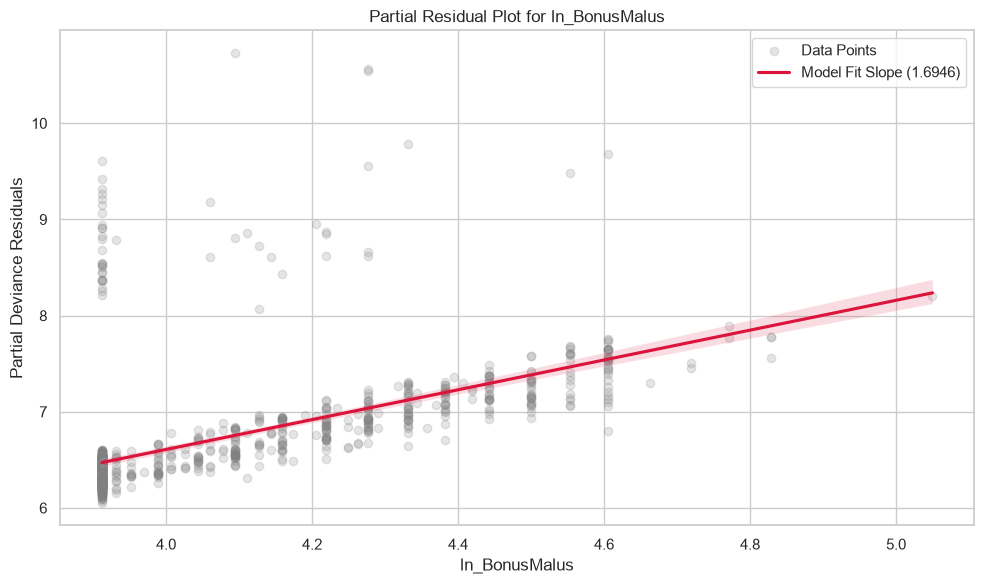

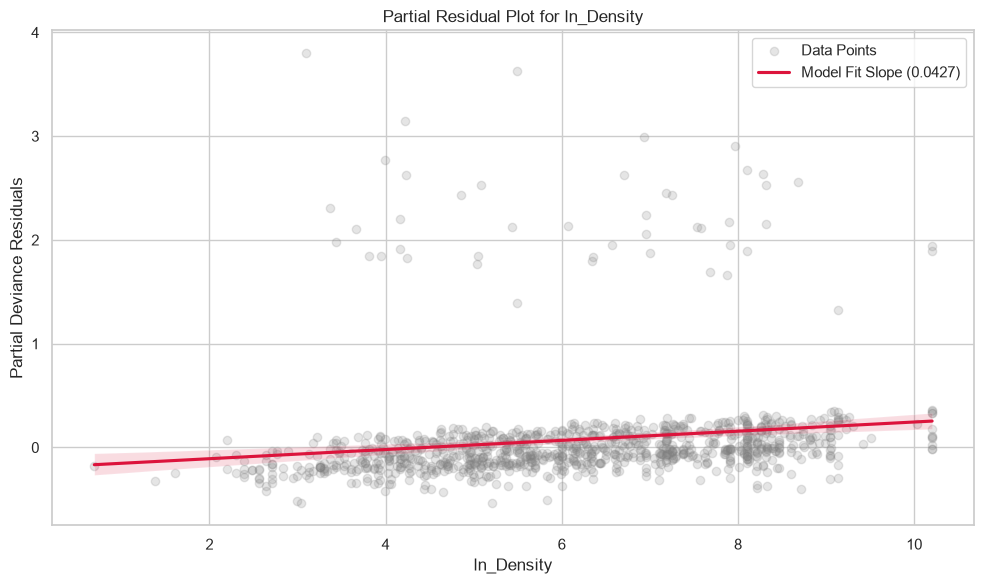

In [12]:
def partial_residual_analysis(model:GLMResultsWrapper, df:pd.DataFrame, df_columns:dict) ->None:
    """
    Conducting of partial residual analysis with plots
    :param model: trained model
    :param df: dataframe
    :param df_columns: dict with columns
    :return:
    """
    print("\nGenerating Partial Residual plots for continuous features...")
    dev_residuals = model.resid_deviance

    for col in df_columns["continuous_cols"]:
        # Formula: Residual + (Beta * Feature_Value)
        beta = model.params[col]
        partial_residuals = dev_residuals + (beta * train_df[col])

        plt.figure()
        # Downsample points for clear visualization performance if data is huge
        sample_idx = df.index
        if len(df) > 1000:
            sample_idx = np.random.choice(train_df.index, size=1000, replace=False)

        plt.scatter(train_df.loc[sample_idx, col], partial_residuals.loc[sample_idx], alpha=0.2, color='gray', label='Data Points')
        sns.regplot(x=train_df.loc[sample_idx, col], y=partial_residuals.loc[sample_idx], scatter=False, color='crimson', label=f'Model Fit Slope ({beta:.4f})')

        plt.title(f"Partial Residual Plot for {col}")
        plt.xlabel(col)
        plt.ylabel("Partial Deviance Residuals")
        plt.legend()
        plt.tight_layout()
        plt.show()

partial_residual_analysis(model, df_transformed, df_transformed_columns)

In [13]:
def test_model_validation(model:GLMResultsWrapper, test_df:pd.DataFrame, df_columns:dict) ->None:
    """
    Model validation on trained model with test data
    :param model: trained model
    :param test_df: dataframe with unseen data for testing
    :return:
    """
    print("---EVALUATING MODEL PERFORMANCE ON UNSEEN TEST DATA---")

    test_predictions = model.predict(exog=test_df, exposure=test_df[df_transformed_columns["exposure_col"]])
    #test_frequency = model.predict(exog=test_df, exposure=1.0)

    actual_test_counts = test_df[df_columns["target_col"]]

    test_mae = mean_absolute_error(actual_test_counts,test_predictions)
    test_rmse = np.sqrt(mean_squared_error(actual_test_counts, test_predictions))

    total_actual_claims = actual_test_counts.sum()
    total_expected_claims = test_predictions.sum()

    print(f"Test Set Mean Absolute Error (MAE) : {test_mae:.5f}")
    print(f"Test Set Root Mean Squared Error (RMSE): {test_rmse:.5f}")
    print("-" * 50)
    print(f"Total Actual Claims in Test Set       : {total_actual_claims}")
    print(f"Total Expected Claims (Model Forecast) : {total_expected_claims:.2f}")
    print(f"Overall Portfolio Balance Ratio        : {(total_expected_claims / total_actual_claims):.4f}")
    print("=" * 50)

test_model_validation(model, test_df, df_transformed_columns)

---EVALUATING MODEL PERFORMANCE ON UNSEEN TEST DATA---
Test Set Mean Absolute Error (MAE) : 0.09827
Test Set Root Mean Squared Error (RMSE): 0.23494
--------------------------------------------------
Total Actual Claims in Test Set       : 7122
Total Expected Claims (Model Forecast) : 7241.46
Overall Portfolio Balance Ratio        : 1.0168


In [15]:
def k_fold_model_validation(formula:str, df:pd.DataFrame, df_columns:dict, n_splits:int) ->np.ndarray:
    """
    K-fold cross-validation of model
    :param formula: formula of a model (it will be trained more times)
    :param df: dataframe
    :param n_splits: number of splits
    :return:
    """

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    oof_predictions = np.zeros(len(df))
    fold_maes = []
    fold_rmses = []
    fold_deviances = [] # Poisson deviances


    print(f"--- Running {n_splits}-Fold Cross-Validation ---")
    for fold, (train_idx, val_idx) in enumerate(kf.split(df_transformed)):
        cv_train = df.iloc[train_idx]
        cv_val = df.iloc[val_idx]

        cv_model = smf.glm(
            formula=formula,
            data=cv_train,
            family=sm.families.Poisson(),
            exposure=cv_train[df_columns["exposure_col"]]
        ).fit()

        fold_preds = cv_model.predict(cv_val) * cv_val[df_columns["exposure_col"]]
        oof_predictions[val_idx] = fold_preds

        mae = mean_absolute_error(cv_val[df_columns["target_col"]], fold_preds)
        rmse = np.sqrt(mean_squared_error(cv_val[df_columns["target_col"]], fold_preds))
        fold_deviance = mean_poisson_deviance(cv_val[df_columns["target_col"]], fold_preds)

        fold_maes.append(mae)
        fold_rmses.append(rmse)
        fold_deviances.append(fold_deviance)

        print(f"Fold {fold+1} MAE: {mae:.5f},  RMSE: {rmse:.5f}, Poisson deviance: {fold_deviance:.5f}")

    print("\n--- Final Cross-Validation Summary ---")
    print(f"Mean Cross-Validated MAE: {np.mean(fold_maes):.5f} (+/- {np.std(fold_maes):.5f})")
    print(f"Mean Cross-Validated RMSE: {np.mean(fold_rmses):.5f} (+/- {np.std(fold_rmses):.5f})")
    print(f"Mean Cross-Validated Poisson deviance: {np.mean(fold_deviances):.5f} (+/- {np.std(fold_deviances):.5f})")
    print("-" * 50)
    print(f"Total number of actual claims:{np.sum(df[df_columns["target_col"]])}")
    print(f"Total number of predicted claims:{np.sum(oof_predictions):.5f}")
    print(f"Overall Portfolio Balance Ratio        : {(np.sum(oof_predictions))/ np.sum(df[df_columns["target_col"]]):.4f}")
    print("=" * 50)

    return oof_predictions

oof_preds_GLM = k_fold_model_validation(formula, df_transformed, df_transformed_columns, 5)

--- Running 5-Fold Cross-Validation ---
Fold 1 MAE: 0.09827,  RMSE: 0.23494, Poisson deviance: 0.31498
Fold 2 MAE: 0.09890,  RMSE: 0.23705, Poisson deviance: 0.31691
Fold 3 MAE: 0.09891,  RMSE: 0.23905, Poisson deviance: 0.31935
Fold 4 MAE: 0.09852,  RMSE: 0.23904, Poisson deviance: 0.31794
Fold 5 MAE: 0.09934,  RMSE: 0.24458, Poisson deviance: 0.32488

--- Final Cross-Validation Summary ---
Mean Cross-Validated MAE: 0.09879 (+/- 0.00037)
Mean Cross-Validated RMSE: 0.23893 (+/- 0.00321)
Mean Cross-Validated Poisson deviance: 0.31881 (+/- 0.00335)
--------------------------------------------------
Total number of actual claims:36090
Total number of predicted claims:36090.39628
Overall Portfolio Balance Ratio        : 1.0000


# XGBoost

## Introduction to XGBoost Modeling

To transition our predictive modeling workflow from traditional parametric regressions to a high-performance machine learning framework, we utilize **XGBoost (Extreme Gradient Boosting)**. XGBoost is an optimized distributed gradient boosting library designed to be highly efficient, flexible, and portable.

While classical linear models require manual feature engineering to capture non-linearities, XGBoost natively uncovers complex interactions and patterns within the data.

### 1. Core Algorithmic Mechanics
XGBoost is an ensemble method that trains decision trees sequentially. Unlike Random Forests, where trees are trained independently in parallel, gradient boosting trains each new tree to predict the *residuals* (errors) of the prior trees combined.

The model optimizes a objective function that balances predictive accuracy with structural complexity to prevent overfitting:

$$\mathcal{L}(\phi) = \sum_{i} l(y_i, \hat{y}_i) + \sum_{k} \Omega(f_k)$$

Where:
* $l(y_i, \hat{y}_i)$ is a differentiable loss function measuring the difference between the prediction $\hat{y}_i$ and the target $y_i$.
* $\Omega(f_k)$ is a regularization term that penalizes the complexity of the trees (e.g., controlling the number of leaves and smooth weighting) to ensure generalizability.

### 2. Custom Objectives and Mathematical Flexibility
One of XGBoost's greatest strengths is its mathematical flexibility. By utilizing a second-order Taylor expansion, the algorithm can optimize *any* custom loss function, provided it is twice differentiable.

When deciding exactly where to split a tree node, the algorithm calculates a structural **Gain score** for a candidate feature using first-order gradients ($g_i$) and second-order Hessians ($h_i$):

$$\text{Gain} = \frac{1}{2} \left[ \frac{(\sum_{i \in L} g_i)^2}{\sum_{i \in L} h_i + \lambda} + \frac{(\sum_{i \in R} g_i)^2}{\sum_{i \in R} h_i + \lambda} - \frac{(\sum_{i \in I} g_i)^2}{\sum_{i \in I} h_i + \lambda} \right] - \gamma$$

Where:
* $L$ and $R$ represent the left and right child nodes after the split, and $I$ represents the parent node.
* $\lambda$ and $\gamma$ are regularization hyperparameters designed to penalize deep or complex splits.

### 3. Feature Importance via Quality Gain
Behind the scenes, the feature importances computed by this framework do not rely on raw split frequencies ("weight"), which tend to heavily bias results toward continuous variables simply because they have infinite split points.

Instead, the model evaluates features using **Gain**, which measures the actual reduction in training loss achieved by splitting a node on a given feature. This ensures that features are fairly judged on their true predictive impact rather than how often they are split.

### 4. Implementation Pipeline Strategy
The following code block implements a robust training and tuning pipeline:
* **Native Categorical Support:** Features are kept as categorical data types, allowing XGBoost to cluster related groups dynamically without requiring massive one-hot encoding data expansion.
* **Bayesian Optimization:** Rather than exhaustive Grid Search, we utilize Bayesian optimization to efficiently map and tune critical regularization hyperparameters (like `max_depth` and `min_child_weight`).
* **Cross-Validation:** $K$-fold cross-validation is integrated directly into the tuning loop to ensure out-of-sample stability and rigorous model validation.

Preparing the data: Needed for XGBoost format:

In [16]:
def prepare_data_for_xgboost(df:pd.DataFrame, df_columns:dict) ->tuple[pd.DataFrame,np.ndarray,pd.Series]:
    """
    Prepares the data for XGBoost model training
    :param df: dataframe
    :param df_columns: dict with columns
    :return: prepared data
    """
    X = df[df_columns["continuous_cols"] + df_columns["categorical_cols"]].copy()
    for col in df_columns["categorical_cols"]:
        X[col] = X[col].astype('category')

    y = df[df_columns["target_col"]].values

    # XGBoost adds the base_margin directly to the link-scale prediction: ln(Expected_Claims) = Margin + Trees
    base_margin = pd.Series(np.log(df[df_columns["exposure_col"]]), index=df.index)
    return X, y, base_margin

X, y, base_margin = prepare_data_for_xgboost(df_transformed, df_transformed_columns)

Hyperparameter tuning with bayesian search:

In [17]:
def tune_xgboost_poisson(X:pd.DataFrame, y:np.ndarray, base_margin:pd.Series, xgb_model:XGBRegressor, search_space:dict) ->tuple[xgb.sklearn.XGBRegressor,dict]:
    """
    Finds best parameters for XGBoost model in search space, and returns the model trained with these parameters.
    It also saves the best parameters and model in two separate .json files
    :param X:
    :param y:
    :param base_margin: This and two params above are the result of prepare_data_for_xgboost
    :param xgb_model: xgb_model that we will train with different set of parameters
    :param search_space: dict containing the possible values of parameters we will combine
    :return: the model with the best parameters
    """
    def poisson_deviance_scorer(estimator, X_val, y_val):
        idx = X_val.index
        predictions = estimator.predict(X_val, base_margin=base_margin[idx])
        return -mean_poisson_deviance(y_val, predictions) # negative because scikit-learn maximizes scores

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    print("Beginning Bayesian Optimization for XGBoost parameters...")
    bayes_search = BayesSearchCV(
        estimator=xgb_model,
        search_spaces=search_space,
        n_iter=25, # Number of parameter combinations to try
        cv=cv,
        scoring=poisson_deviance_scorer,
        n_jobs=-1,
        random_state=42
    )

    # We must pass base_margin via fit_params mapping to the underlying model
    bayes_search.fit(X, y, base_margin=base_margin)

    print("\nBest Hyperparameters Found:")
    for param, val in bayes_search.best_params_.items():
        print(f" - {param}: {val}")
    with open('xgboost_best_params.json', 'w') as f:
        json.dump(bayes_search.best_params_, f, indent=4)
    print("-> Hyperparameters saved to xgboost_best_params.json")

    best_model = bayes_search.best_estimator_
    best_model.save_model('xgboost_poisson_model.json')
    print("-> Trained model saved to 'xgboost_poisson_model.json'")

    return best_model, bayes_search.best_params_

    # Initialize the XGBoost Regressor with native categorical support and Poisson objective

xgb_model = xgb.XGBRegressor(
    objective='count:poisson',
    enable_categorical=True,
    tree_method='hist',
    random_state=42
)

# Define the search space based on business sensitivity (avoiding overly deep trees)
search_space = {
    'max_depth': Integer(3, 7),                  # Controls interaction depth
    'min_child_weight': Integer(10, 100),        # Higher values prevent modeling noise in rare claims
    'learning_rate': Real(0.01, 0.2, prior='log-uniform'),
    'subsample': Real(0.6, 1.0),                 # Row subsampling for regularization
    'colsample_bytree': Real(0.6, 1.0),          # Column subsampling
    'reg_alpha': Real(1e-3, 10.0, prior='log-uniform'),  # L1 regularization
    'reg_lambda': Real(1e-3, 10.0, prior='log-uniform')  # L2 regularization
}

# Best estimator extraction:
best_xgb_model, best_params = tune_xgboost_poisson(X, y, base_margin, xgb_model, search_space)

Beginning Bayesian Optimization for XGBoost parameters...

Best Hyperparameters Found:
 - colsample_bytree: 1.0
 - learning_rate: 0.2
 - max_depth: 7
 - min_child_weight: 10
 - reg_alpha: 0.001
 - reg_lambda: 10.0
 - subsample: 1.0
-> Hyperparameters saved to xgboost_best_params.json
-> Trained model saved to 'xgboost_poisson_model.json'


Production training with cross validation and diagnostics:

Starting 5-fold cross-validation...
Fold 1 MAE: 0.09575,  RMSE: 0.23382, Poisson deviance: 0.29974
Fold 2 MAE: 0.09626,  RMSE: 0.23545, Poisson deviance: 0.30065
Fold 3 MAE: 0.09620,  RMSE: 0.23690, Poisson deviance: 0.30168
Fold 4 MAE: 0.09578,  RMSE: 0.23745, Poisson deviance: 0.30111
Fold 5 MAE: 0.09676,  RMSE: 0.24305, Poisson deviance: 0.30800

--- Final Cross-Validation Summary ---
Mean Cross-Validated MAE: 0.09615 (+/- 0.00037)
Mean Cross-Validated RMSE: 0.23733 (+/- 0.00312)
Mean Cross-Validated Poisson deviance: 0.30223 (+/- 0.00295)
--------------------------------------------------
Total number of actual claims: 36090
Total number of predicted claims: 36167.96051
Overall Portfolio Balance Ratio        : 1.0022


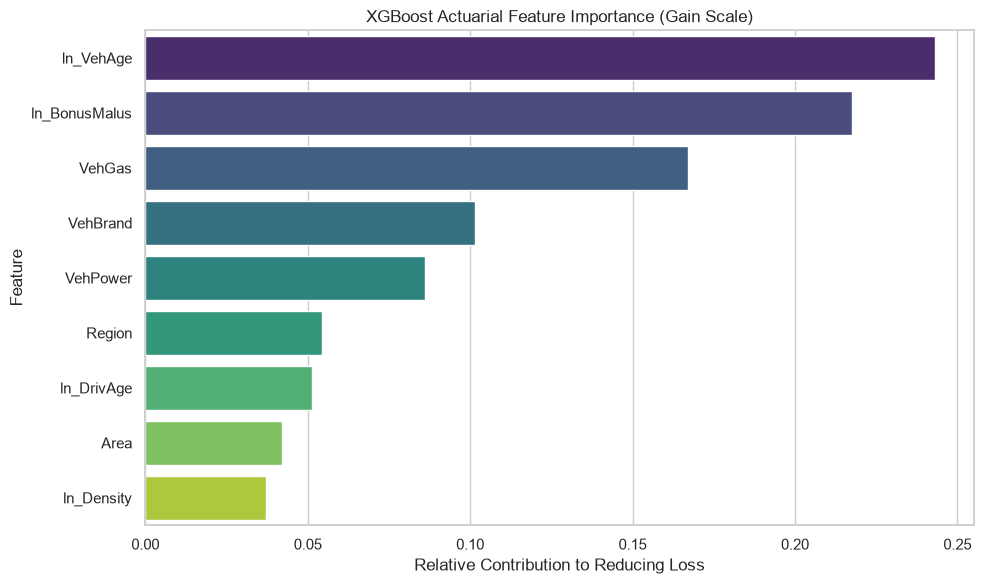

In [18]:
def train_and_evaluate_cv(X:pd.DataFrame, y:np.ndarray, base_margin:pd.Series, model:XGBRegressor) ->tuple[np.ndarray,pd.DataFrame]:
    """
    Trains the model with the best hyperparameters and does k-fold cross-validation
    :param X:
    :param y:
    :param base_margin: This and two params above are the result of prepare_data_for_xgboost
    :param model: the model with the best hyperparameters
    :return:
    """

    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    oof_predictions = np.zeros(len(y))
    fold_maes = []
    fold_rmses = []
    fold_deviances = []
    feature_importances = np.zeros(X.shape[1])

    print("Starting 5-fold cross-validation...")

    for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
        X_train, y_train = X.iloc[train_idx], y[train_idx]
        X_val, y_val = X.iloc[val_idx], y[val_idx]

        margin_train = base_margin.iloc[train_idx]
        margin_val = base_margin.iloc[val_idx]

        model.fit(
            X_train, y_train,
            base_margin=margin_train,
            eval_set=[(X_val, y_val)],
            base_margin_eval_set=[margin_val],
            verbose=False
        )

        # Predict out-of-sample
        fold_preds = model.predict(X_val, base_margin=margin_val)
        oof_predictions[val_idx] = fold_preds

        # Calculate metrics
        mae = mean_absolute_error(y_val, fold_preds)
        rmse = np.sqrt(mean_squared_error(y_val, fold_preds))
        fold_deviance = mean_poisson_deviance(y_val, fold_preds)

        fold_maes.append(mae)
        fold_rmses.append(rmse)
        fold_deviances.append(fold_deviance)
        feature_importances += model.feature_importances_ / kf.n_splits

        print(f"Fold {fold+1} MAE: {mae:.5f},  RMSE: {rmse:.5f}, Poisson deviance: {fold_deviance:.5f}")

    print("\n--- Final Cross-Validation Summary ---")
    print(f"Mean Cross-Validated MAE: {np.mean(fold_maes):.5f} (+/- {np.std(fold_maes):.5f})")
    print(f"Mean Cross-Validated RMSE: {np.mean(fold_rmses):.5f} (+/- {np.std(fold_rmses):.5f})")
    print(f"Mean Cross-Validated Poisson deviance: {np.mean(fold_deviances):.5f} (+/- {np.std(fold_deviances):.5f})")
    print("-" * 50)
    print(f"Total number of actual claims: {np.sum(y)}")
    print(f"Total number of predicted claims: {np.sum(oof_predictions):.5f}")
    print(f"Overall Portfolio Balance Ratio        : {(np.sum(oof_predictions) / np.sum(y)):.4f}")
    print("=" * 50)

    # --- Visualization: Actuarial Business Sensibility (Feature Importance) ---
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': feature_importances
    }).sort_values(by='Importance', ascending=False)

    plt.figure()
    sns.barplot(x='Importance', y='Feature', hue='Feature', data=importance_df, palette='viridis', legend=False)
    plt.title('XGBoost Actuarial Feature Importance (Gain Scale)')
    plt.xlabel('Relative Contribution to Reducing Loss')
    plt.tight_layout()
    plt.show()

    return oof_predictions, importance_df

# loading the best parameters trained with
with open("xgboost_best_params.json", "r") as f:
    best_params = json.load(f)

model = xgb.XGBRegressor(
            objective='count:poisson',
            enable_categorical=True,
            tree_method='hist',
            **best_params,
            random_state=42
        )

#oof_preds, feature_imp = train_and_evaluate_cv(X, y, base_margin, best_xgb_model)
oof_preds_XGBoost, feature_imp_XGBoost = train_and_evaluate_cv(X, y, base_margin, model)

It can be seen that the most and the least important parameters are of continual nature. This shows one advantage that XGBoost has over the basic tree-based learners such as random forest: it doesn't give unfair advantage regarding importance to continual variables (which is the case because of infinite possible threshold/cut values).

VehAge, BonusMalus and to some extent VehGas seem to have much greater predictive power than the resto of the variables. The reasons can be numerous: Vehicle age is naturally tightly connected to the probability of any kind of failure. Bonus/malus is derived from a driver's history of incidents (or the absence of it). It seems reasonable that some drivers are by nature less responsible and therefore riskier than others. Vehicle fuel type has an interesting property: its influence could be easily dismissed by looking directly at the plot of claim number versus it. That shows the reason why we must be _very_ careful when removing, or transforming variables.

## Analysis

Both models perform very similarly, strictly based on metrics (the practically perfect score is probably not a significantly different from XGBoost results, but rather pure luck). However, there are many more things to consider when choosing a model:
- **Interpretability**: Both models have their advantages regarding interpretability. With GLMs, we can analyze everything by looking at the coefficients and their statistics. The influence of the sign of each coefficient was mentioned earlier. Mentioned statistics are mostly basic, so more people will understand them. XGBoost, as many tree-based methods, opens the door to the notion of the feature importance. The ways of calculating them may not be known by everyone, but the ending results are easy to explain to the general population, which is _extremely_ important in an actuary world.

- **Complexity**: GLMs are easy to implement from start to model training, as the underlying maths is easier. When using XGBoost, the greater portion of the job is left to the library functions. This means that GLMs can often be easier for diagnostics, as we can investigate more details. On the other hand, XGBoost provides us with many optimized and well documented processes which are leaving less space for mistake.

- **Speed of training/retraining**: XGBoost was trained much faster, which can be seen when performing K-fold cross validation. This becomes relevant when a more complex validation techniques, and more complex data processing in general, is involved.

In [19]:
def analyze_top_poisson_errors(df_original:pd.DataFrame,X_features:pd.DataFrame,y_actual:np.ndarray, oof_predictions:np.ndarray, exposure_col:str="Exposure") -> pd.DataFrame:
    """
    Calculates individual Poisson deviance residuals, extracts the top 10 worst
    model mispredictions, and attaches their structural features for audit. The assumed
    model is XGBoost
    :param df_original: dataframe
    :param X_features:
    :param y_actual: this and X_features are obtained in data preparation for XGBoost model
    :param oof_predictions:
    :param exposure_col:
    :return:
    """

    # Avoid divide-by-zero or log(0) issues by adding a tiny epsilon to predictions
    eps = 1e-7
    y_pred = np.clip(oof_predictions, eps, None)

    # formula for Unit Poisson Deviance Residuals:
    # d_i = 2 * (y * log(y / y_pred) - (y - y_pred))
    # Where y is actual claim count, and y_pred is expected claim count
    with np.errstate(divide="ignore", invalid="ignore"):
        deviance_components = y_actual * np.log(y_actual / y_pred) - (
            y_actual - y_pred
        )
        # handle the mathematical limit when actual claim count is exactly 0
        deviance_components = np.where(
            y_actual == 0, y_pred, deviance_components
        )
        deviance_residuals = 2 * deviance_components

    # Diagnostic dataframe
    diagnostic_df = X_features.copy()

    diagnostic_df["Actual_Claims"] = y_actual
    diagnostic_df["Predicted_Claims"] = y_pred
    diagnostic_df["Exposure"] = df_original[exposure_col].values

    diagnostic_df["Actual_Frequency"] = (
        diagnostic_df["Actual_Claims"] / diagnostic_df["Exposure"]
    )
    diagnostic_df["Predicted_Frequency"] = (
        diagnostic_df["Predicted_Claims"] / diagnostic_df["Exposure"]
    )

    diagnostic_df["Absolute_Poisson_Deviance"] = np.abs(deviance_residuals)
    diagnostic_df["Error_Direction"] = np.where(
        y_actual > y_pred, "Underpredicted", "Overpredicted"
    )

    # Sort and isolate the top 10 highest deviance rows
    top_10_errors = diagnostic_df.sort_values(
        by="Absolute_Poisson_Deviance", ascending=False
    ).head(10)

    print("--- TOP 10 MODEL MISPREDICTIONS (POISSON DEVIANCE) ---")
    print(top_10_errors[
                [
                    "Actual_Claims",
                    "Predicted_Claims",
                    "Exposure",
                    "Actual_Frequency",
                    "Predicted_Frequency",
                    "Absolute_Poisson_Deviance",
                    "Error_Direction",
                ]
            ]
        )

    return top_10_errors

top10 = analyze_top_poisson_errors(df_transformed,X,y,oof_preds_XGBoost)

--- TOP 10 MODEL MISPREDICTIONS (POISSON DEVIANCE) ---
        Actual_Claims  Predicted_Claims  Exposure  Actual_Frequency  \
321248             16          0.364026  0.330000         48.484848   
6539               11          0.069432  1.000000         11.000000   
488270             11          0.081391  0.070000        157.142857   
487268             11          0.111513  0.080000        137.500000   
321512              9          0.121432  0.080000        112.500000   
501990              4          0.007811  0.100000         40.000000   
3328                3          0.001149  0.010000        300.000000   
46470               5          0.080158  1.000000          5.000000   
3360                2          0.000338  0.002732        732.000000   
344616              5          0.089059  0.080000         62.500000   

        Predicted_Frequency  Absolute_Poisson_Deviance Error_Direction  
321248             1.103109                  89.787840  Underpredicted  
6539             

The results are saying that the model is quite bad at predicting the high claim number. This problem can be addressed in several ways - but the most basic ones would include adding a weighting factor to each observation: higher the ClaimNb, greater the weight. This should be done with a great care: such method could get us closer to these extreme cases but get away from the most of them. The one who makes models should decide what is more important. In general, pessimistic estimates cause less damage than the optimistic ones. 